<a href="https://colab.research.google.com/github/LepingWan/ECE247A/blob/main/HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem 1

**(a)** Minimizing the reconstruction error makes $W^TWx$ close to $x$. Since the reconstruction is computed from the compressed representation $Wx$, a small error means that $Wx$ retains enough information to approximately recover $x$.

**(b)** Define
$$
h=Wx,\qquad \hat{x}=W^Th,\qquad e=\hat{x}-x,\qquad L=\frac12e^Te.
$$
The computational graph is:

```text
W ------------+
              v
x ---------> [Wx] -> h -----> [W^T h] -> x_hat -> [x_hat - x] -> e -> [e^T e / 2] -> L
                                ^                    ^
W -----> [transpose] -----------+                    |
x --------------------------------------------------+
```

Both occurrences of $W$ refer to the same matrix.

**(c)** Temporarily separate the two occurrences:
$$
F(A,B)=\frac12\|B^TAx-x\|^2,\qquad L(W)=F(W,W).
$$
By the chain rule,
$$
\frac{\partial L}{\partial W_{ij}}
=\left.\frac{\partial F}{\partial A_{ij}}\right|_{A=B=W}
+\left.\frac{\partial F}{\partial B_{ij}}\right|_{A=B=W}.
$$
Thus, the gradient contributions from the encoder and decoder paths must be added.

**(d)** Starting from the loss,
$$
\frac{\partial L}{\partial \hat{x}}=e.
$$
For the decoder, $\hat{x}_i=\sum_j W_{ji}h_j$, so its contribution is
$$
\left(\frac{\partial L}{\partial W_{ji}}\right)_{\mathrm{decoder}}=e_i h_j,
\qquad (\nabla_WL)_{\mathrm{decoder}}=he^T.
$$
The gradient reaching $h$ is
$$
\frac{\partial L}{\partial h}=We.
$$
Since $h=Wx$, the encoder contribution is
$$
(\nabla_WL)_{\mathrm{encoder}}=(We)x^T.
$$
Adding the two,
$$
\boxed{\nabla_WL=(Wx)(W^TWx-x)^T+W(W^TWx-x)x^T.}
$$
Both terms have shape $m\times n$, matching $W$.


# Problem 2

Write
$$
K=\alpha XX^T+\beta^{-1}I.
$$
Since $K$ is symmetric, $K^{-T}=K^{-1}$.

**(a)** The computational graph for $L_1$ is:

```text
X ----------------------+
|                       v
+-> [transpose] -> X^T -> [multiply] -> XX^T -> [times alpha] -> [+ beta^(-1) I] -> K
                                                                                 |
                                                                                 v
L1 <- [times (-D/2)] <- [log] <- [determinant] <------------------------------------+
```

**(b)** First differentiate with respect to $K$:
$$
\frac{\partial L_1}{\partial K}=-\frac D2K^{-T}=-\frac D2K^{-1}.
$$
To backpropagate through $K=\alpha XX^T+\beta^{-1}I$, let
$$
G=\frac{\partial L_1}{\partial K}.
$$
Since
$$
K_{ij}=\alpha\sum_k X_{ik}X_{jk}+\beta^{-1}\delta_{ij},
$$
each $X_{ab}$ contributes through both factors:
$$
\frac{\partial L_1}{\partial X_{ab}}
=\alpha\sum_jG_{aj}X_{jb}+\alpha\sum_iG_{ia}X_{ib}.
$$
In matrix form,
$$
\frac{\partial L_1}{\partial X}=\alpha(G+G^T)X.
$$
Here $G$ is symmetric, giving
$$
\boxed{\frac{\partial L_1}{\partial X}=-\alpha D K^{-1}X.}
$$

**(c)** The computational graph for $L_2$ is:

```text
X ----------------------+
|                       v
+-> [transpose] -> X^T -> [multiply] -> XX^T -> [times alpha] -> [+ beta^(-1) I] -> K
                                                                                 |
                                                                                 v
                                                                             [inverse]
                                                                                 |
                                                                                 v
Y ----------------------+                                                       K^(-1)
|                       v                                                        |
+-> [transpose] -> Y^T -> [multiply] -> YY^T --------------------------------+     |
                                                                           v     v
                                                                           [multiply]
                                                                                |
                                                                                v
                                                                             [trace]
                                                                                |
                                                                                v
                                                                          [times (-1/2)]
                                                                                |
                                                                                v
                                                                                L2
```

**(d)** Let $Q=K^{-1}$. Then
$$
L_2=-\frac12\operatorname{tr}(QYY^T).
$$
Using $\partial\operatorname{tr}(QA)/\partial Q=A^T$,
$$
\frac{\partial L_2}{\partial Q}=-\frac12(YY^T)^T=-\frac12YY^T.
$$
Using the inverse derivative given in the problem,
$$
\frac{\partial L_2}{\partial K}
=-K^{-1}\frac{\partial L_2}{\partial K^{-1}}K^{-1}
=\frac12K^{-1}YY^TK^{-1}.
$$
This matrix is symmetric. Applying the same chain rule through $XX^T$ as in part (b),
$$
\begin{aligned}
\frac{\partial L_2}{\partial X}
&=\alpha\left(\frac{\partial L_2}{\partial K}+\left(\frac{\partial L_2}{\partial K}\right)^T\right)X\\
&=\boxed{\alpha K^{-1}YY^TK^{-1}X}.
\end{aligned}
$$

**(e)** The constant $-c$ has zero derivative, so
$$
\begin{aligned}
\frac{\partial L}{\partial X}
&=\frac{\partial L_1}{\partial X}+\frac{\partial L_2}{\partial X}\\
&=\boxed{\alpha\left(K^{-1}YY^TK^{-1}-DK^{-1}\right)X}.
\end{aligned}
$$


# Problem 3

**(a)** Define
$$
z=W_1x+b_1,\qquad h=\sigma(z),\qquad u=W_2h+b_2,\qquad \hat{y}=u+x.
$$

```text
        W1        b1                       W2        b2
         v         v                        v         v
x ---> [W1 x] --> [+] -> z -> [sigmoid] -> h -> [W2 h] -> [+] -> u --> [+] -> y_hat
|                                                                    ^        |
+-------------------------- identity --------------------------------+        v
                                                                         [y_hat - y] <-- y
                                                                              |
                                                                              v
                                                                              e
                                                                              |
                                                                              v
                                                                         [e^T e / 2]
                                                                              |
                                                                              v
                                                                              L
```

**(b)** Let
$$
e=\hat{y}-y=W_2h+b_2+x-y.
$$
Then
$$
\frac{\partial L}{\partial\hat{y}}=e.
$$
The addition $\hat{y}=u+x$ passes the same gradient to $u$:
$$
\frac{\partial L}{\partial u}=e.
$$
Since $u_i=\sum_j(W_2)_{ij}h_j+(b_2)_i$,
$$
\frac{\partial L}{\partial(W_2)_{ij}}=e_i h_j.
$$
Thus,
$$
\boxed{\nabla_{W_2}L=eh^T.}
$$

**(c)** Since $\partial u_i/\partial(b_2)_j=\delta_{ij}$,
$$
\boxed{\nabla_{b_2}L=e=\hat{y}-y.}
$$
The residual connection changes the value of $\hat{y}$, and hence $e$, but the local derivative with respect to $b_2$ is still the identity.

**(d)** Backpropagating through $u=W_2h+b_2$,
$$
\frac{\partial L}{\partial h}=W_2^Te.
$$
For the sigmoid,
$$
\sigma'(z_i)=\sigma(z_i)(1-\sigma(z_i))=h_i(1-h_i).
$$
Applying the chain rule element by element,
$$
\frac{\partial L}{\partial z_i}=(W_2^Te)_i h_i(1-h_i).
$$
Let
$$
\delta=(W_2^Te)\odot h\odot(1-h),
$$
where $\odot$ means element-wise multiplication.

Since $z_i=\sum_j(W_1)_{ij}x_j+(b_1)_i$,
$$
\frac{\partial L}{\partial(W_1)_{ij}}=\delta_i x_j.
$$
Therefore,
$$
\boxed{\nabla_{W_1}L=\left[(W_2^Te)\odot h\odot(1-h)\right]x^T.}
$$
The skip connection affects this gradient through
$$
e=W_2h+b_2+x-y.
$$
There is no separate skip-path term for $W_1$, because the added $x$ does not depend on $W_1$.

**(e)** Since $\partial z_i/\partial(b_1)_j=\delta_{ij}$,
$$
\boxed{\nabla_{b_1}L=(W_2^Te)\odot h\odot(1-h).}
$$


## Two-layer neural network - Homework #3

**Neural Networks & Deep Learning - ECE C147A/C247A, UCLA Fall 2026**  
**Instructor:** Prof. Suhas Diggavi  
**TAs:** A. Kadiyala, B. Huang, M.Y. Turali, K. Pang, S.Y. Yetim  
**Released:** Monday, October 12, 2026  
**Due:** Friday, October 23, 2026, 11:59 PM Pacific Time  
**HW3 Problem 4:** 30 points

Please follow the notebook linearly to implement a two layer neural network.

Please print out the workbook entirely when completed.

We thank Serena Yeung & Justin Johnson for permission to use code written for the CS 231n class (cs231n.stanford.edu).  These are the functions in the cs231n folders and code in the jupyer notebook to preprocess and show the images.  The classifiers used are based off of code prepared for CS 231n as well.

The goal of this workbook is to give you experience with training a two layer neural network.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

def rel_error(x, y):
    return np.max(np.abs(x - y) / np.maximum(1e-8, np.abs(x) + np.abs(y)))


Matplotlib is building the font cache; this may take a moment.


## Toy example

Before loading CIFAR-10, there will be a toy example to test your implementation of the forward and backward pass

In [2]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, std=1e-4):
        self.params = {
            'W1': std * np.random.randn(hidden_size, input_size),
            'b1': np.zeros(hidden_size),
            'W2': std * np.random.randn(output_size, hidden_size),
            'b2': np.zeros(output_size),
        }

    def loss(self, X, y=None, reg=0.0):
        W1, b1 = self.params['W1'], self.params['b1']
        W2, b2 = self.params['W2'], self.params['b2']
        N = X.shape[0]

        hidden = np.maximum(0, X @ W1.T + b1)
        scores = hidden @ W2.T + b2
        if y is None:
            return scores

        # Subtract the largest score before exponentiating.
        shifted = scores - np.max(scores, axis=1, keepdims=True)
        log_probs = shifted - np.log(np.sum(np.exp(shifted), axis=1, keepdims=True))
        loss = -np.mean(log_probs[np.arange(N), y])
        loss += 0.5 * reg * (np.sum(W1 * W1) + np.sum(W2 * W2))

        dscores = np.exp(log_probs)
        dscores[np.arange(N), y] -= 1
        dscores /= N
        grads = {}
        grads['W2'] = dscores.T @ hidden + reg * W2
        grads['b2'] = np.sum(dscores, axis=0)
        dhidden = dscores @ W2
        dhidden[hidden <= 0] = 0
        grads['W1'] = dhidden.T @ X + reg * W1
        grads['b1'] = np.sum(dhidden, axis=0)
        return loss, grads

    def train(self, X, y, X_val, y_val, learning_rate=1e-3,
              learning_rate_decay=0.95, reg=1e-5, num_iters=100,
              batch_size=200, verbose=False):
        num_train = X.shape[0]
        iterations_per_epoch = max(num_train // batch_size, 1)
        loss_history, train_acc_history, val_acc_history = [], [], []
        best_val_acc = -1.0
        best_params = None
        best_iteration = 0

        for it in range(num_iters):
            indices = np.random.choice(num_train, batch_size, replace=True)
            X_batch, y_batch = X[indices], y[indices]
            loss, grads = self.loss(X_batch, y_batch, reg=reg)
            loss_history.append(float(loss))
            for name in self.params:
                self.params[name] -= learning_rate * grads[name]

            if verbose and (it % 500 == 0 or it == num_iters - 1):
                print('iteration %d / %d: loss %.4f' % (it, num_iters, loss))

            if (it + 1) % iterations_per_epoch == 0 or it == num_iters - 1:
                train_acc = np.mean(self.predict(X_batch) == y_batch)
                val_acc = np.mean(self.predict(X_val) == y_val)
                train_acc_history.append(float(train_acc))
                val_acc_history.append(float(val_acc))
                if val_acc > best_val_acc:
                    best_val_acc = float(val_acc)
                    best_iteration = it + 1
                    best_params = {name: value.copy() for name, value in self.params.items()}
                learning_rate *= learning_rate_decay

        return {
            'loss_history': loss_history,
            'train_acc_history': train_acc_history,
            'val_acc_history': val_acc_history,
            'best_val_acc': best_val_acc,
            'best_params': best_params,
            'best_iteration': best_iteration,
        }

    def predict(self, X):
        return np.argmax(self.loss(X), axis=1)


In [3]:
# Create a small net and some toy data to check your implementations.
# Note that we set the random seed for repeatable experiments.

input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
    np.random.seed(0)
    return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
    np.random.seed(1)
    X = 10 * np.random.randn(num_inputs, input_size)
    y = np.array([0, 1, 2, 2, 1])
    return X, y

net = init_toy_model()
X, y = init_toy_data()

### Compute forward pass scores

In [4]:
## Implement the forward pass of the neural network.

# Note, there is a statement if y is None: return scores, which is why 
# the following call will calculate the scores.
scores = net.loss(X)
print('Your scores:')
print(scores)
print()
print('correct scores:')
correct_scores = np.asarray([
    [-1.07260209,  0.05083871, -0.87253915],
    [-2.02778743, -0.10832494, -1.52641362],
    [-0.74225908,  0.15259725, -0.39578548],
    [-0.38172726,  0.10835902, -0.17328274],
    [-0.64417314, -0.18886813, -0.41106892]])
print(correct_scores)
print()

# The difference should be very small. We get < 1e-7
print('Difference between your scores and correct scores:')
print(np.sum(np.abs(scores - correct_scores)))
assert np.sum(np.abs(scores - correct_scores)) < 1e-7


Your scores:
[[-1.07260209  0.05083871 -0.87253915]
 [-2.02778743 -0.10832494 -1.52641362]
 [-0.74225908  0.15259725 -0.39578548]
 [-0.38172726  0.10835902 -0.17328274]
 [-0.64417314 -0.18886813 -0.41106892]]

correct scores:
[[-1.07260209  0.05083871 -0.87253915]
 [-2.02778743 -0.10832494 -1.52641362]
 [-0.74225908  0.15259725 -0.39578548]
 [-0.38172726  0.10835902 -0.17328274]
 [-0.64417314 -0.18886813 -0.41106892]]

Difference between your scores and correct scores:
3.381231214460989e-08


### Forward pass loss

In [5]:
loss, _ = net.loss(X, y, reg=0.05)
correct_loss = 1.071696123862817

# should be very small, we get < 1e-12
print('Difference between your loss and correct loss:')
print(np.sum(np.abs(loss - correct_loss)))
assert abs(loss - correct_loss) < 1e-12


Difference between your loss and correct loss:
0.0


In [6]:
print(loss)

1.071696123862817


### Backward pass

Implements the backwards pass of the neural network.  Check your gradients with the gradient check utilities provided.

In [7]:
def eval_numerical_gradient(f, x, verbose=True, h=0.00001):
  """ 
  a naive implementation of numerical gradient of f at x 
  - f should be a function that takes a single argument
  - x is the point (numpy array) to evaluate the gradient at
  """ 

  fx = f(x) # evaluate function value at original point
  grad = np.zeros_like(x)
  # iterate over all indexes in x
  it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
  while not it.finished:

    # evaluate function at x+h
    ix = it.multi_index
    oldval = x[ix]
    x[ix] = oldval + h # increment by h
    fxph = f(x) # evalute f(x + h)
    x[ix] = oldval - h
    fxmh = f(x) # evaluate f(x - h)
    x[ix] = oldval # restore

    # compute the partial derivative with centered formula
    grad[ix] = (fxph - fxmh) / (2 * h) # the slope
    if verbose:
      print(ix, grad[ix])
    it.iternext() # step to next dimension

  return grad

# Use numeric gradient checking to check your implementation of the backward pass.
# If your implementation is correct, the difference between the numeric and
# analytic gradients should be less than 1e-8 for each of W1, W2, b1, and b2.

loss, grads = net.loss(X, y, reg=0.05)

# these should all be less than 1e-8 or so
for param_name in grads:
    f = lambda W: net.loss(X, y, reg=0.05)[0]
    param_grad_num = eval_numerical_gradient(f, net.params[param_name], verbose=False)
    print('{} max relative error: {}'.format(param_name, rel_error(param_grad_num, grads[param_name])))
    assert rel_error(param_grad_num, grads[param_name]) < 1e-8


W2 max relative error: 2.96322045694799e-10
b2 max relative error: 1.616097450384273e-09
W1 max relative error: 1.283274044162582e-09
b1 max relative error: 3.172680864678023e-09


### Training the network

Implement neural_net.train() to train the network via stochastic gradient descent, much like the softmax and SVM.

Final training loss:  0.014497864587765875


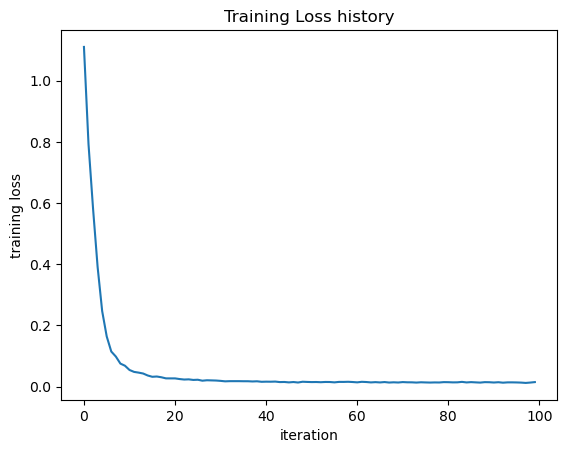

In [8]:
net = init_toy_model()
stats = net.train(X, y, X, y,
            learning_rate=1e-1, reg=5e-6,
            num_iters=100, verbose=False)

print('Final training loss: ', stats['loss_history'][-1])

# plot the loss history
plt.plot(stats['loss_history'])
plt.xlabel('iteration')
plt.ylabel('training loss')
plt.title('Training Loss history')
plt.show()

## Classify CIFAR-10

Do classification on the CIFAR-10 dataset.

Dataset: [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html), Alex Krizhevsky, *Learning Multiple Layers of Features from Tiny Images* (2009). The next cell downloads the Python archive if needed.


In [9]:
import hashlib
import pickle
import tarfile
from pathlib import Path
from urllib.request import urlretrieve


def load_CIFAR10(root):
    # Same image layout as the supplied cs231n loader, using float32 to save memory.
    def load_batch(filename):
        with open(Path(root) / filename, 'rb') as f:
            batch = pickle.load(f, encoding='latin1')
        images = batch['data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
        return images.astype(np.float32), np.array(batch['labels'])

    batches = [load_batch('data_batch_%d' % i) for i in range(1, 6)]
    X_train = np.concatenate([batch[0] for batch in batches])
    y_train = np.concatenate([batch[1] for batch in batches])
    X_test, y_test = load_batch('test_batch')
    return X_train, y_train, X_test, y_test


def prepare_CIFAR10():
    root = Path('cifar-10-batches-py')
    if not (root / 'test_batch').exists():
        archive = Path('cifar-10-python.tar.gz')
        if not archive.exists():
            print('Downloading CIFAR-10...')
            urlretrieve('https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz', archive)
        with open(archive, 'rb') as f:
            checksum = hashlib.file_digest(f, 'md5').hexdigest()
        if checksum != 'c58f30108f718f92721af3b95e74349a':
            raise ValueError('CIFAR-10 download is incomplete; remove the archive and rerun.')
        with tarfile.open(archive, 'r:gz') as f:
            f.extractall(path='.', filter='data')
    return root


def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    """
    Load the CIFAR-10 dataset from disk and perform preprocessing to prepare
    it for the two-layer neural net classifier. These are the same steps as
    we used for the SVM, but condensed to a single function.  
    """
    # Load the raw CIFAR-10 data
    cifar10_dir = prepare_CIFAR10()
    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)
        
    # Subsample the data
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    # Normalize the data: subtract the mean image
    mean_image = np.mean(X_train, axis=0)
    X_train -= mean_image
    X_val -= mean_image
    X_test -= mean_image

    # Reshape data to rows
    X_train = X_train.reshape(num_training, -1)
    X_val = X_val.reshape(num_validation, -1)
    X_test = X_test.reshape(num_test, -1)

    return X_train, y_train, X_val, y_val, X_test, y_test


# Invoke the above function to get our data.
X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()
print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Train data shape:  (49000, 3072)
Train labels shape:  (49000,)
Validation data shape:  (1000, 3072)
Validation labels shape:  (1000,)
Test data shape:  (1000, 3072)
Test labels shape:  (1000,)


### Running SGD

If your implementation is correct, you should see a validation accuracy of around 28-29%.

In [10]:
np.random.seed(42)
input_size = 32 * 32 * 3
hidden_size = 50
num_classes = 10
net = TwoLayerNet(input_size, hidden_size, num_classes)
# Float32 is enough for CIFAR training; the toy gradient checks above use float64.
net.params = {name: value.astype(np.float32) for name, value in net.params.items()}

stats = net.train(X_train, y_train, X_val, y_val,
                 num_iters=1000, batch_size=200,
                 learning_rate=1e-4, learning_rate_decay=0.95,
                 reg=0.25, verbose=True)
val_acc = np.mean(net.predict(X_val) == y_val)
print('Validation accuracy:', val_acc)
subopt_net = net


iteration 0 / 1000: loss 2.3028


iteration 500 / 1000: loss 2.0827


iteration 999 / 1000: loss 1.9969
Validation accuracy: 0.289


## Questions:

The training accuracy isn't great.  

(1) What are some of the reasons why this is the case?  Take the following cell to do some analyses and then report your answers in the cell following the one below.

(2) How should you fix the problems you identified in (1)?


In [11]:
stats['train_acc_history']

[0.2, 0.22, 0.185, 0.365, 0.25]

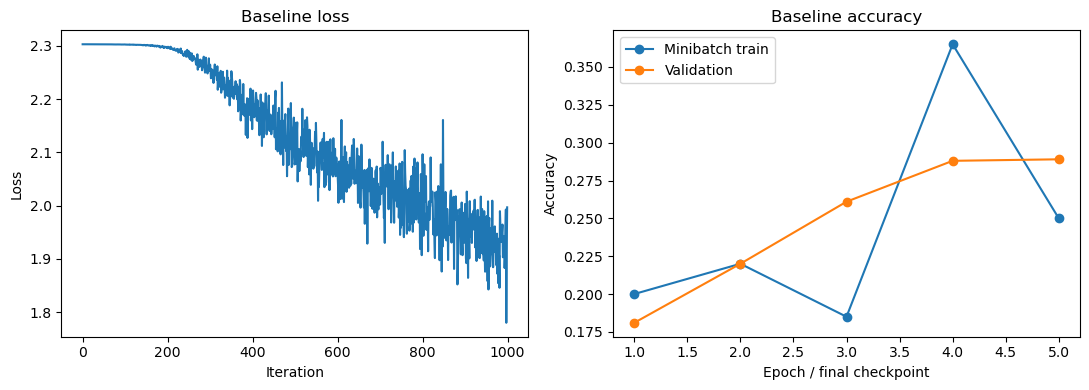

Full training accuracy: 0.2933265306122449
Validation accuracy: 0.289
Mean loss, first 100 iterations: 2.302603340148926
Mean loss, last 100 iterations: 1.938121690750122
W1 standard deviation: 0.0002686229
W2 standard deviation: 0.004384665


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(stats['loss_history'])
axes[0].set(xlabel='Iteration', ylabel='Loss', title='Baseline loss')
epochs = np.arange(1, len(stats['train_acc_history']) + 1)
axes[1].plot(epochs, stats['train_acc_history'], 'o-', label='Minibatch train')
axes[1].plot(epochs, stats['val_acc_history'], 'o-', label='Validation')
axes[1].set(xlabel='Epoch / final checkpoint', ylabel='Accuracy', title='Baseline accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()

# Check full-training accuracy too, since minibatch accuracy is noisy.
print('Full training accuracy:', np.mean(subopt_net.predict(X_train) == y_train))
print('Validation accuracy:', np.mean(subopt_net.predict(X_val) == y_val))
print('Mean loss, first 100 iterations:', np.mean(stats['loss_history'][:100]))
print('Mean loss, last 100 iterations:', np.mean(stats['loss_history'][-100:]))
for name in ('W1', 'W2'):
    print(name, 'standard deviation:', np.std(subopt_net.params[name]))


## Answers:

(1) The full training accuracy is 29.3% and the validation accuracy is 28.9%, so the main problem is underfitting or slow optimization rather than a large train/validation gap. The loss is still decreasing at the end of the run. The learning rate is small, and 1000 updates cover only about four epochs. Also, the initial weights have standard deviation $10^{-4}$, so the initial hidden activations and weight gradients are small.

(2) I trained longer and tried larger learning rates, a larger initial weight scale, and different regularization strengths. The best setting used a learning rate of $8\times10^{-4}$, regularization of $0.15$, and initial weight standard deviation of $0.01$. Training for 10000 updates with learning-rate decay of $0.97$ per epoch gave a best validation accuracy of 52.3%. I kept the hidden layer at 50 units and used only the validation set to choose the settings and checkpoint.


## Optimize the neural network

Use the following part of the Jupyter notebook to optimize your hyperparameters on the validation set.  Store your nets as best_net.

lr = 0.0008, reg = 0.05: best val = 0.519 at iteration 9800


lr = 0.0008, reg = 0.15: best val = 0.523 at iteration 9800


lr = 0.0012, reg = 0.05: best val = 0.509 at iteration 7350


lr = 0.0012, reg = 0.15: best val = 0.518 at iteration 8820
Best (learning rate, regularization): (0.0008, 0.15)
Best validation accuracy: 0.523


Best full training accuracy: 0.5969795918367347


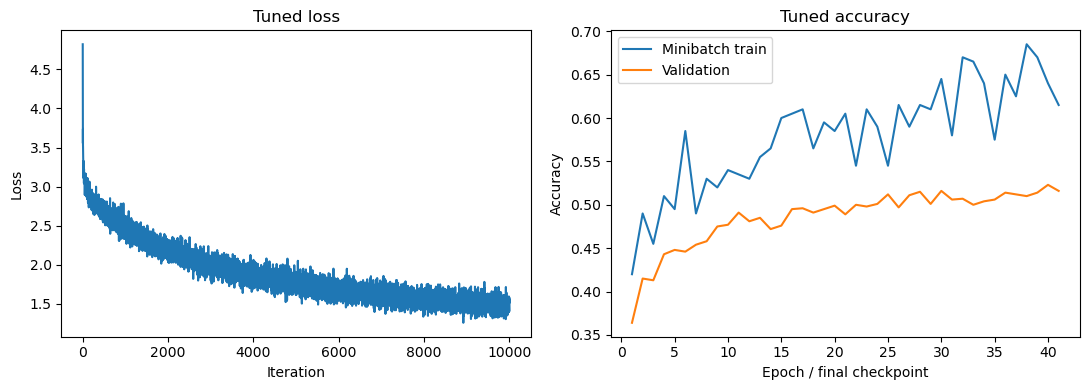

In [13]:
# Keep the same 3072 -> 50 -> 10 network and use minibatch SGD.
# Choose the learning rate and regularization using only the validation set.
configs = [
    (8e-4, 0.05),
    (8e-4, 0.15),
    (1.2e-3, 0.05),
    (1.2e-3, 0.15),
]
best_net = None
best_val_acc = -1
best_stats = None
results = []

for learning_rate, reg in configs:
    # Use the same initialization and minibatch sequence for each setting.
    np.random.seed(123)
    candidate = TwoLayerNet(input_size, 50, num_classes, std=1e-2)
    candidate.params = {name: value.astype(np.float32)
                        for name, value in candidate.params.items()}
    candidate_stats = candidate.train(
        X_train, y_train, X_val, y_val,
        learning_rate=learning_rate, learning_rate_decay=0.97,
        reg=reg, num_iters=10000, batch_size=200, verbose=False)

    # Restore the epoch with the highest validation accuracy for this run.
    candidate.params = {name: value.copy()
                        for name, value in candidate_stats['best_params'].items()}
    candidate_val_acc = np.mean(candidate.predict(X_val) == y_val)
    results.append((learning_rate, reg, candidate_val_acc))
    print('lr = %.4g, reg = %.3g: best val = %.3f at iteration %d' %
          (learning_rate, reg, candidate_val_acc, candidate_stats['best_iteration']))
    if candidate_val_acc > best_val_acc:
        best_val_acc = candidate_val_acc
        best_net = candidate
        best_stats = candidate_stats
        best_config = (learning_rate, reg)

print('Best (learning rate, regularization):', best_config)
print('Best validation accuracy:', best_val_acc)
print('Best full training accuracy:', np.mean(best_net.predict(X_train) == y_train))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(best_stats['loss_history'])
axes[0].set(xlabel='Iteration', ylabel='Loss', title='Tuned loss')
epochs = np.arange(1, len(best_stats['train_acc_history']) + 1)
axes[1].plot(epochs, best_stats['train_acc_history'], label='Minibatch train')
axes[1].plot(epochs, best_stats['val_acc_history'], label='Validation')
axes[1].set(xlabel='Epoch / final checkpoint', ylabel='Accuracy', title='Tuned accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()


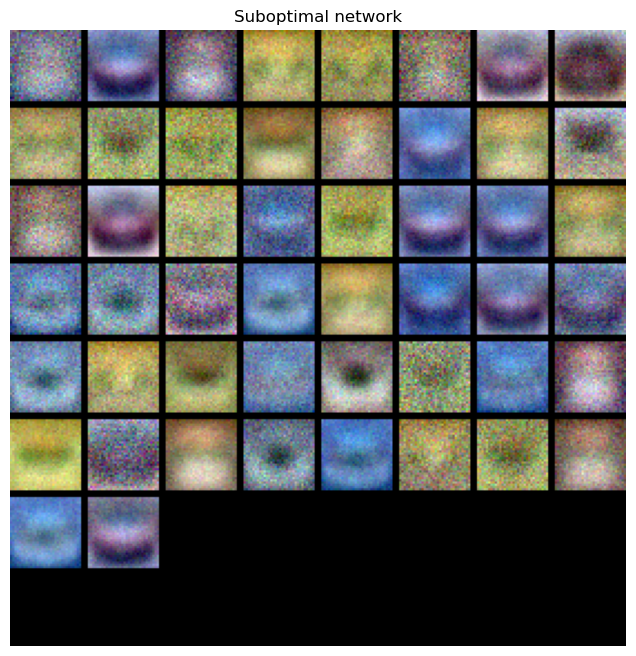

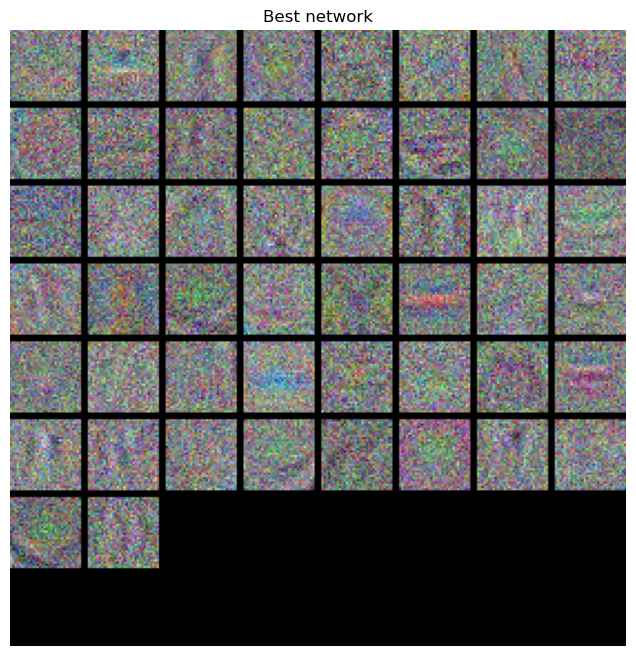

In [14]:
from math import sqrt, ceil
import numpy as np

def visualize_grid(Xs, ubound=255.0, padding=1):
  """
  Reshape a 4D tensor of image data to a grid for easy visualization.

  Inputs:
  - Xs: Data of shape (N, H, W, C)
  - ubound: Output grid will have values scaled to the range [0, ubound]
  - padding: The number of blank pixels between elements of the grid
  """
  (N, H, W, C) = Xs.shape
  grid_size = int(ceil(sqrt(N)))
  grid_height = H * grid_size + padding * (grid_size - 1)
  grid_width = W * grid_size + padding * (grid_size - 1)
  grid = np.zeros((grid_height, grid_width, C))
  next_idx = 0
  y0, y1 = 0, H
  for y in np.arange(grid_size):
    x0, x1 = 0, W
    for x in np.arange(grid_size):
      if next_idx < N:
        img = Xs[next_idx]
        low, high = np.min(img), np.max(img)
        grid[y0:y1, x0:x1] = ubound * (img - low) / max(high - low, 1e-8)
        # grid[y0:y1, x0:x1] = Xs[next_idx]
        next_idx += 1
      x0 += W + padding
      x1 += W + padding
    y0 += H + padding
    y1 += H + padding
  # grid_max = np.max(grid)
  # grid_min = np.min(grid)
  # grid = ubound * (grid - grid_min) / (grid_max - grid_min)
  return grid


def show_net_weights(net, title):
    W1 = net.params['W1'].reshape(50, 32, 32, 3)
    plt.figure(figsize=(8, 8))
    plt.imshow(visualize_grid(W1, padding=3).astype('uint8'))
    plt.title(title)
    plt.axis('off')
    plt.show()

show_net_weights(subopt_net, 'Suboptimal network')
show_net_weights(best_net, 'Best network')


## Question:

(1) What differences do you see in the weights between the suboptimal net and the best net you arrived at?

## Answer:

(1) The suboptimal network has several similar smooth color and light/dark blobs. The best network's filters look more varied but also noisier. I used a larger initial weight scale for the tuned network, so more random texture remains visible. Despite this, it has higher validation accuracy; smoother-looking individual filters do not necessarily give a better classifier. Each filter is scaled separately in the plot, so brightness alone does not compare the actual weight magnitudes.


## Evaluate on test set 

In [15]:
test_acc = (best_net.predict(X_test) == y_test).mean()
print('Test accuracy: ', test_acc)

Test accuracy:  0.499
